# 📉 Prédiction du churn client — Telco Customer Churn

**Auteur :** *Faugué Titouan* · **Type :** projet personnel de Data Science · **Stack :** Python, pandas, scikit-learn, XGBoost, seaborn

---

## 🎯 Contexte et objectif

Un opérateur télécom perd chaque mois une partie de ses clients (*churn*). Acquérir un nouveau client coûte généralement bien plus cher que d'en retenir un existant : **identifier à l'avance les clients à risque** permet de leur proposer une action de rétention ciblée (remise, changement de contrat, support dédié…).

**Objectif du projet :**
1. Comprendre **quels facteurs** sont associés au départ des clients (analyse exploratoire).
2. Construire un **modèle de classification** qui estime la probabilité de churn de chaque client.
3. Traduire le modèle en **décision métier** : choisir un seuil qui maximise le gain d'une campagne de rétention.

**Données :** [IBM Telco Customer Churn](https://www.kaggle.com/datasets/blastchar/telco-customer-churn) — 7 043 clients, 21 variables (profil, services souscrits, contrat, facturation, churn).

## 📑 Sommaire
1. Imports et configuration
2. Chargement et aperçu des données
3. Nettoyage
4. Analyse exploratoire (EDA)
5. Feature engineering
6. Préparation des données pour la modélisation
7. Modèles de référence et comparaison
8. Optimisation des hyperparamètres
9. Évaluation finale sur le jeu de test
10. Choix du seuil de décision orienté métier
11. Interprétabilité du modèle
12. Recommandations métier
13. Sauvegarde du modèle
14. Conclusion et pistes d'amélioration

## 1. Imports et configuration

In [1]:
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, average_precision_score, classification_report,
                             f1_score, precision_recall_curve, precision_score, recall_score,
                             roc_auc_score, roc_curve)
from sklearn.model_selection import (GridSearchCV, RandomizedSearchCV, StratifiedKFold,
                                     cross_val_predict, cross_validate, train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")

# Chemins du projet
DATA_PATH = Path("../data/telco_customer_churn.csv")
IMG_DIR = Path("../images")
MODEL_DIR = Path("../models")
IMG_DIR.mkdir(exist_ok=True)
MODEL_DIR.mkdir(exist_ok=True)

# Reproductibilité
RANDOM_STATE = 42

# Style graphique homogène
sns.set_theme(style="whitegrid", context="notebook")
PALETTE = {"No": "#2E86AB", "Yes": "#E63946"}
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 13})

def save_fig(name):
    """Sauvegarde la figure courante dans /images (utilisée dans le README)."""
    plt.savefig(IMG_DIR / f"{name}.png", bbox_inches="tight", dpi=130)

pd.set_option("display.max_columns", 30)

## 2. Chargement et aperçu des données

> 💡 Le fichier Kaggle d'origine porte l'extension `.xls` mais il s'agit en réalité d'un **CSV**. Il a été renommé `telco_customer_churn.csv` dans le dossier `data/`.

| Groupe | Variables |
|---|---|
| **Identifiant** | `customerID` |
| **Profil client** | `gender`, `SeniorCitizen`, `Partner`, `Dependents` |
| **Ancienneté** | `tenure` (nombre de mois en tant que client) |
| **Services** | `PhoneService`, `MultipleLines`, `InternetService`, `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies` |
| **Contrat & facturation** | `Contract`, `PaperlessBilling`, `PaymentMethod`, `MonthlyCharges`, `TotalCharges` |
| **Cible** | `Churn` (le client est-il parti le mois dernier ?) |

In [2]:
df = pd.read_csv(DATA_PATH)
print(f"Dimensions : {df.shape[0]} lignes × {df.shape[1]} colonnes")
df.head()

Dimensions : 7043 lignes × 21 colonnes


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [4]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


## 3. Nettoyage

### 3.1 La colonne `TotalCharges`
`TotalCharges` est lue comme du texte (`object`) alors qu'elle devrait être numérique : certaines valeurs contiennent un espace vide. On la convertit en numérique pour identifier les lignes problématiques.

In [ ]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Valeurs manquantes dans TotalCharges :", df["TotalCharges"].isnull().sum())
df.loc[df["TotalCharges"].isnull(), ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

Valeurs manquantes dans TotalCharges : 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


Les 11 lignes concernées ont toutes un **`tenure` égal à 0** : ce sont des clients qui viennent de s'abonner et qui n'ont encore reçu aucune facture. Leur montant total facturé est donc logiquement **0**, ce qui justifie l'imputation par 0 plutôt que par la moyenne ou la suppression.

In [6]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)

# Vérifications de qualité
print("Valeurs manquantes restantes :", df.isnull().sum().sum())
print("Doublons :", df.duplicated().sum())
print("customerID uniques :", df["customerID"].is_unique)

Valeurs manquantes restantes : 0
Doublons : 0
customerID uniques : True


### 3.2 Harmonisation
`SeniorCitizen` est codée 0/1 alors que toutes les autres variables binaires sont en `Yes`/`No`. On l'harmonise pour la lisibilité de l'analyse.

In [7]:
df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})
df["SeniorCitizen"].value_counts()

SeniorCitizen
No     5901
Yes    1142
Name: count, dtype: int64

## 4. Analyse exploratoire (EDA)

### 4.1 Distribution de la variable cible

       Nombre  Pourcentage (%)
Churn                         
No       5174             73.5
Yes      1869             26.5


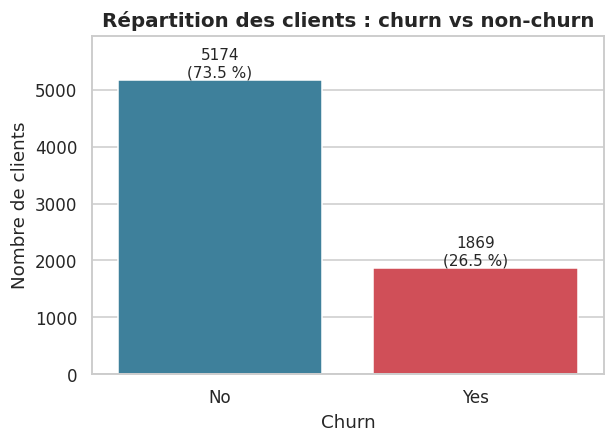

In [8]:
churn_counts = df["Churn"].value_counts()
churn_pct = df["Churn"].value_counts(normalize=True) * 100
print(pd.DataFrame({"Nombre": churn_counts, "Pourcentage (%)": churn_pct.round(1)}))

fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df, x="Churn", palette=PALETTE, order=["No", "Yes"], ax=ax)
for p, pct in zip(ax.patches, churn_pct[["No", "Yes"]]):
    ax.annotate(f"{int(p.get_height())}\n({pct:.1f} %)", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom", fontsize=10)
ax.set_title("Répartition des clients : churn vs non-churn")
ax.set_xlabel("Churn"); ax.set_ylabel("Nombre de clients")
ax.set_ylim(0, churn_counts.max() * 1.15)
save_fig("01_churn_distribution")
plt.show()

**Constat :** environ **26,5 %** des clients sont partis. Les classes sont **déséquilibrées** : un modèle qui prédirait toujours « No » aurait déjà ~73 % d'accuracy tout en étant inutile. On privilégiera donc des métriques adaptées : **ROC-AUC, rappel, précision et F1** sur la classe churn.

### 4.2 Variables numériques

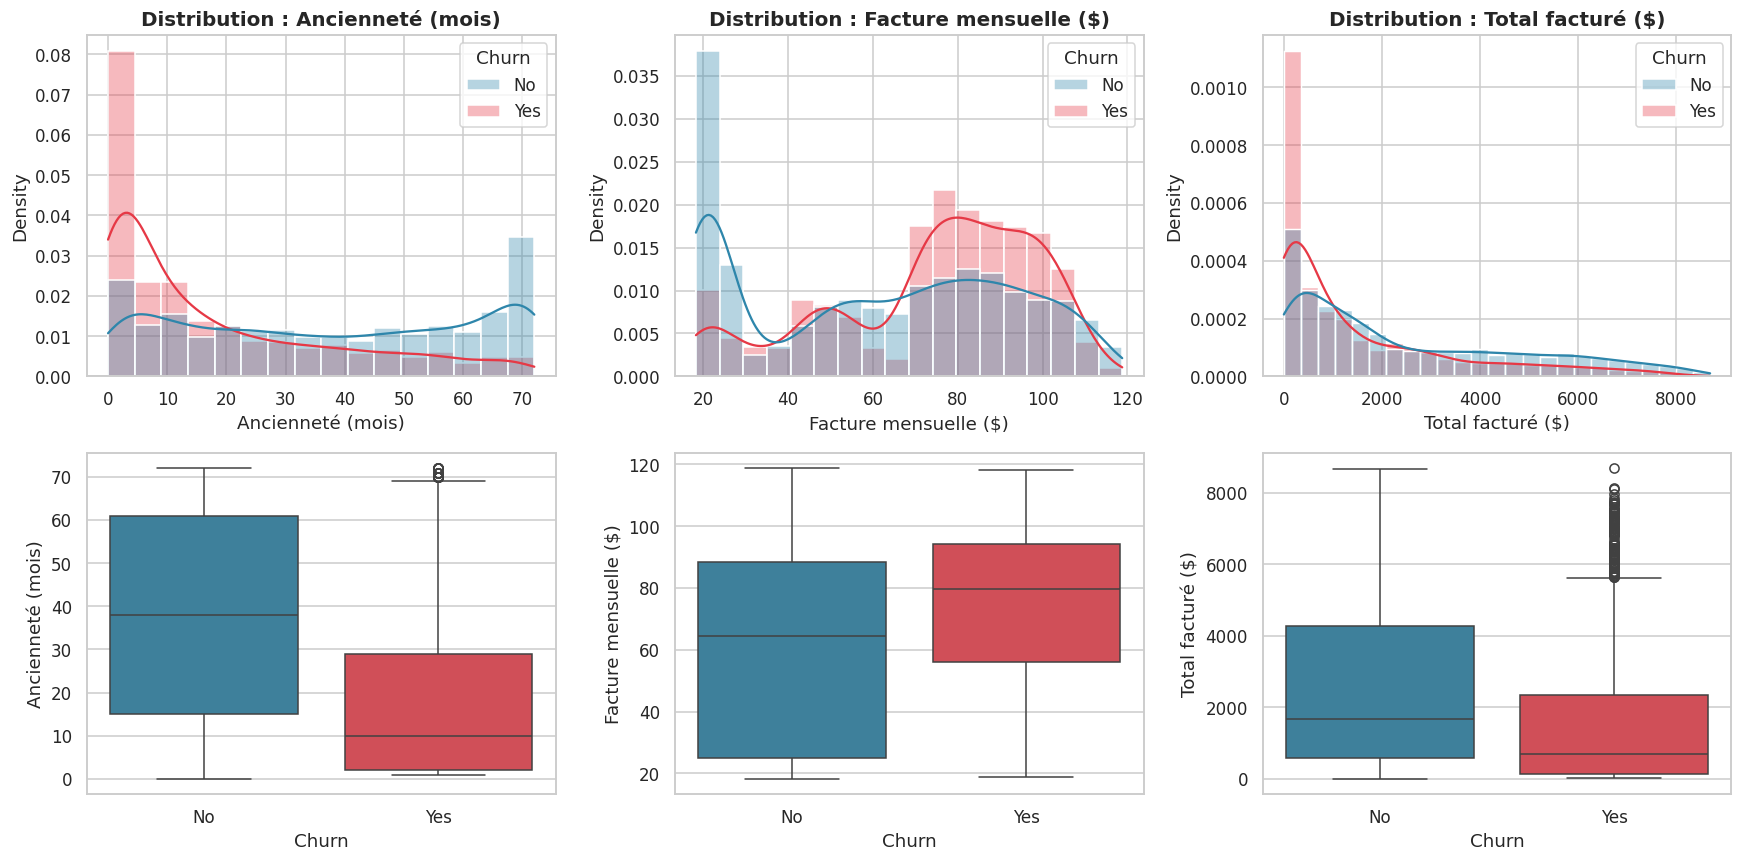

,tenure,MonthlyCharges,TotalCharges
Churn,,,
No,38.0,64.4,1679.5
Yes,10.0,79.6,703.6


In [9]:
num_vars = ["tenure", "MonthlyCharges", "TotalCharges"]
labels = {"tenure": "Ancienneté (mois)", "MonthlyCharges": "Facture mensuelle ($)", "TotalCharges": "Total facturé ($)"}

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for i, var in enumerate(num_vars):
    sns.histplot(data=df, x=var, hue="Churn", palette=PALETTE, kde=True, stat="density",
                 common_norm=False, alpha=0.35, ax=axes[0, i])
    axes[0, i].set_title(f"Distribution : {labels[var]}")
    axes[0, i].set_xlabel(labels[var])
    sns.boxplot(data=df, x="Churn", y=var, palette=PALETTE, order=["No", "Yes"], ax=axes[1, i])
    axes[1, i].set_ylabel(labels[var])
plt.tight_layout()
save_fig("02_numeric_distributions")
plt.show()

df.groupby("Churn")[num_vars].median().round(1)

**Constats :**
- **`tenure`** : les clients qui partent sont très majoritairement **récents** (médiane ~10 mois contre ~38 mois pour ceux qui restent). Le risque est concentré sur les premiers mois.
- **`MonthlyCharges`** : les clients qui partent ont des **factures mensuelles plus élevées** (médiane ~80 $ contre ~64 $).
- **`TotalCharges`** : plus faible chez les churners, mais c'est surtout une conséquence de leur faible ancienneté (`TotalCharges ≈ tenure × MonthlyCharges`).

### 4.3 Taux de churn selon les variables catégorielles
Plutôt que de compter les clients, on affiche le **taux de churn** de chaque modalité, ce qui permet de comparer directement des groupes de tailles différentes. La ligne pointillée représente le taux moyen.

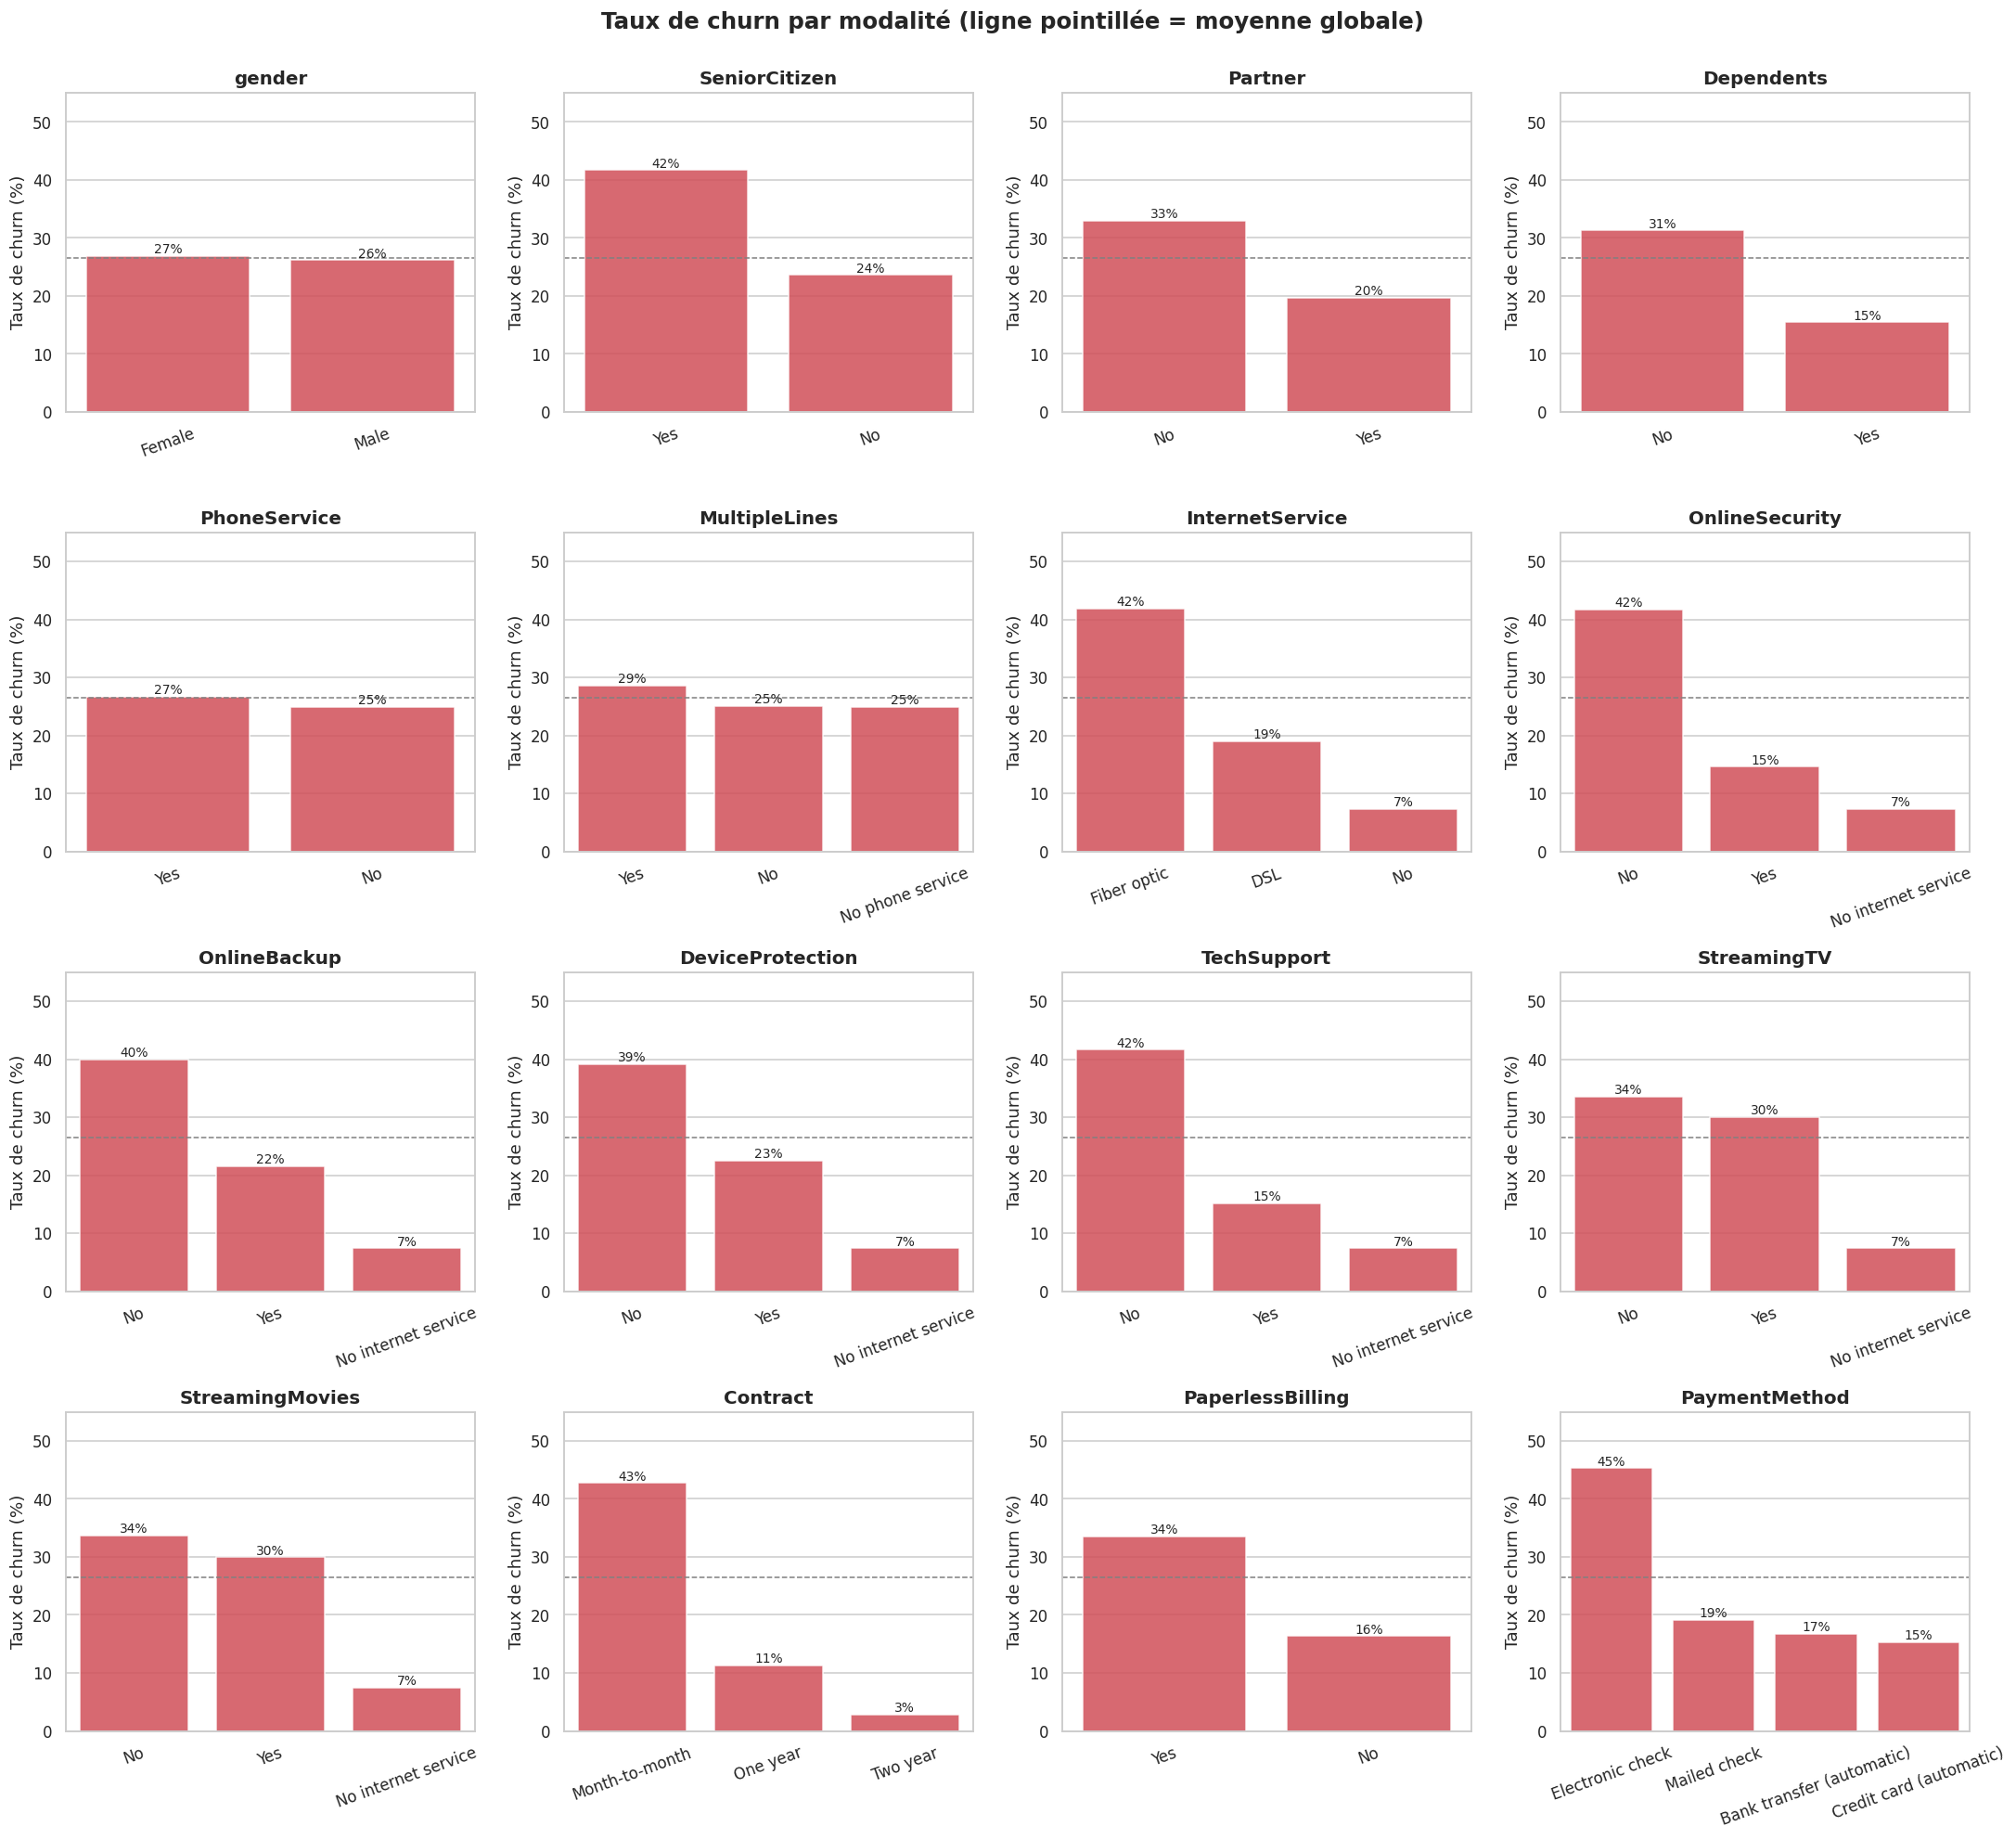

In [10]:
cat_vars = ["gender", "SeniorCitizen", "Partner", "Dependents", "PhoneService", "MultipleLines",
            "InternetService", "OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport",
            "StreamingTV", "StreamingMovies", "Contract", "PaperlessBilling", "PaymentMethod"]
global_rate = (df["Churn"] == "Yes").mean() * 100

fig, axes = plt.subplots(4, 4, figsize=(20, 18))
for ax, var in zip(axes.flat, cat_vars):
    rate = df.groupby(var)["Churn"].apply(lambda s: (s == "Yes").mean() * 100).sort_values(ascending=False)
    sns.barplot(x=rate.index, y=rate.values, color="#E63946", alpha=0.85, ax=ax)
    ax.axhline(global_rate, ls="--", color="grey", lw=1)
    ax.set_title(var); ax.set_ylabel("Taux de churn (%)"); ax.set_xlabel("")
    ax.set_ylim(0, 55)
    ax.tick_params(axis="x", rotation=20)
    for p in ax.patches:
        ax.annotate(f"{p.get_height():.0f}%", (p.get_x() + p.get_width() / 2, p.get_height()),
                    ha="center", va="bottom", fontsize=9)
plt.suptitle("Taux de churn par modalité (ligne pointillée = moyenne globale)", fontsize=16, fontweight="bold", y=1.0)
plt.tight_layout()
save_fig("03_churn_rate_by_category")
plt.show()

Zoom sur les trois variables les plus discriminantes : **type de contrat**, **service Internet** et **moyen de paiement**.

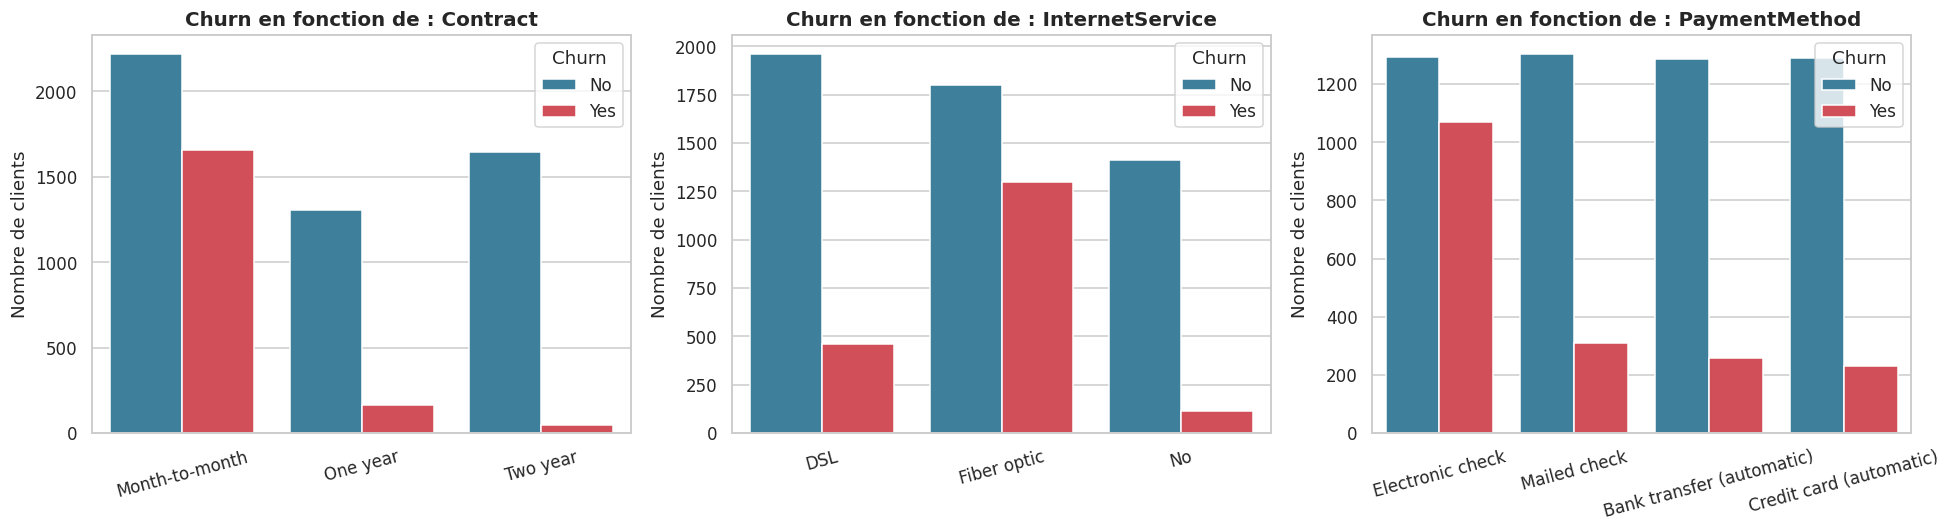

Churn             No   Yes
Contract                  
Month-to-month  57.3  42.7
One year        88.7  11.3
Two year        97.2   2.8 

Churn              No   Yes
InternetService            
DSL              81.0  19.0
Fiber optic      58.1  41.9
No               92.6   7.4 

Churn                        No   Yes
PaymentMethod                        
Bank transfer (automatic)  83.3  16.7
Credit card (automatic)    84.8  15.2
Electronic check           54.7  45.3
Mailed check               80.9  19.1 



In [11]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, var in zip(axes, ["Contract", "InternetService", "PaymentMethod"]):
    sns.countplot(data=df, x=var, hue="Churn", palette=PALETTE, hue_order=["No", "Yes"], ax=ax)
    ax.set_title(f"Churn en fonction de : {var}")
    ax.set_xlabel(""); ax.set_ylabel("Nombre de clients")
    ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
save_fig("04_contract_internet_payment")
plt.show()

for var in ["Contract", "InternetService", "PaymentMethod"]:
    print(pd.crosstab(df[var], df["Churn"], normalize="index").mul(100).round(1), "\n")

**Constats :**
- **Contrat** : c'est le facteur le plus marquant. Les contrats **mensuels** ont un taux de churn d'environ **43 %**, contre ~11 % pour un an et ~3 % pour deux ans.
- **Internet** : les clients **Fibre optique** partent beaucoup plus (~42 %) que les clients DSL (~19 %) — alors que c'est l'offre premium. Cela peut signaler un problème de **prix** ou de **qualité de service**.
- **Paiement** : le **chèque électronique** est associé à ~45 % de churn, bien au-dessus des paiements automatiques (~15-17 %).
- **Services d'accompagnement** : l'absence d'`OnlineSecurity` ou de `TechSupport` est associée à un churn nettement plus élevé (~42 %).
- **`gender`** et **`PhoneService`** n'ont quasiment aucun effet.
- Les **seniors** et les clients **sans partenaire ni personne à charge** partent davantage.

### 4.4 Churn selon l'ancienneté

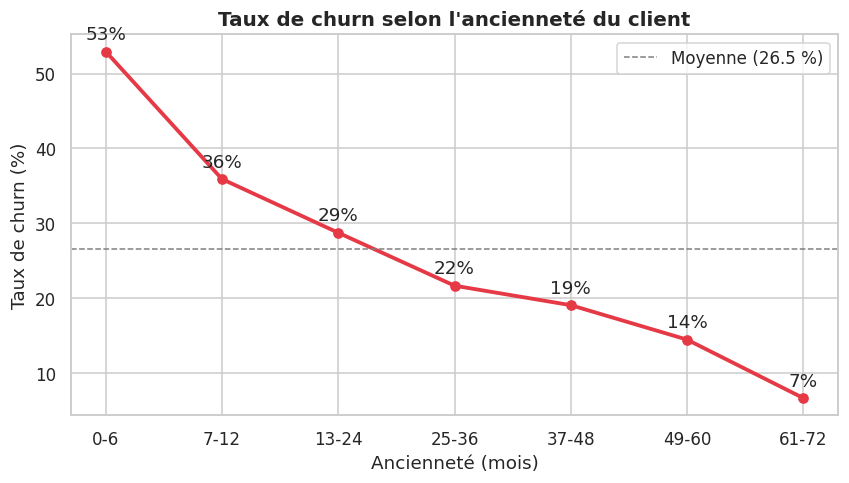

In [12]:
bins = [0, 6, 12, 24, 36, 48, 60, 72]
tenure_labels = ["0-6", "7-12", "13-24", "25-36", "37-48", "49-60", "61-72"]
df_tmp = df.assign(tenure_group=pd.cut(df["tenure"], bins=bins, labels=tenure_labels, include_lowest=True))
rate_by_tenure = df_tmp.groupby("tenure_group", observed=True)["Churn"].apply(lambda s: (s == "Yes").mean() * 100)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(rate_by_tenure.index.astype(str), rate_by_tenure.values, marker="o", color="#E63946", lw=2.5)
for x, y in zip(rate_by_tenure.index.astype(str), rate_by_tenure.values):
    ax.annotate(f"{y:.0f}%", (x, y), textcoords="offset points", xytext=(0, 8), ha="center")
ax.axhline(global_rate, ls="--", color="grey", lw=1, label=f"Moyenne ({global_rate:.1f} %)")
ax.set_title("Taux de churn selon l'ancienneté du client")
ax.set_xlabel("Ancienneté (mois)"); ax.set_ylabel("Taux de churn (%)")
ax.legend()
save_fig("05_churn_by_tenure")
plt.show()

Le risque de churn est **maximal durant les 6 premiers mois** (plus d'un client sur deux) puis décroît fortement avec l'ancienneté. **L'onboarding des nouveaux clients est donc un levier clé.**

### 4.5 Contrat × ancienneté × facture mensuelle

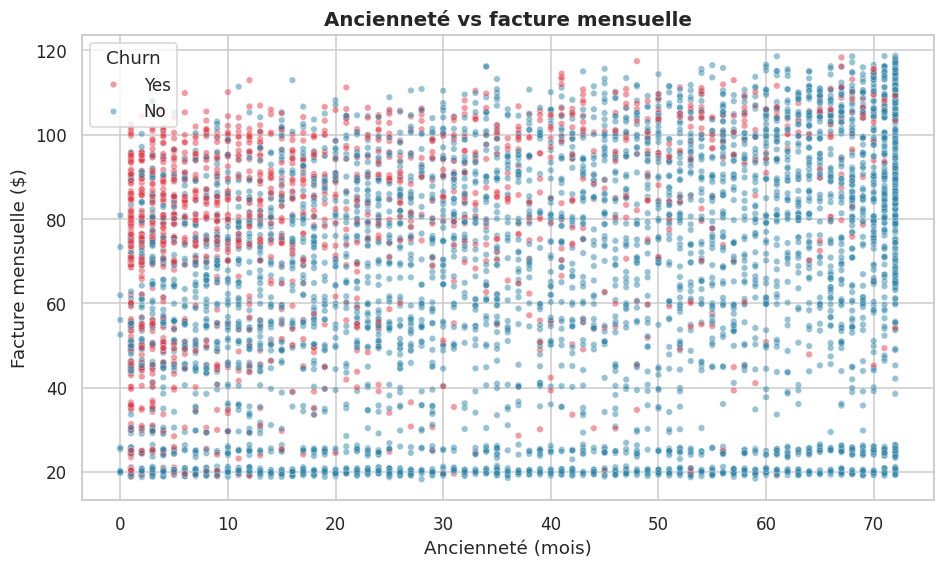

In [13]:
fig, ax = plt.subplots(figsize=(10, 5.5))
sns.scatterplot(data=df.sample(frac=1, random_state=RANDOM_STATE), x="tenure", y="MonthlyCharges",
                hue="Churn", palette=PALETTE, alpha=0.5, s=18, ax=ax)
ax.set_title("Ancienneté vs facture mensuelle")
ax.set_xlabel("Ancienneté (mois)"); ax.set_ylabel("Facture mensuelle ($)")
save_fig("06_tenure_vs_charges")
plt.show()

Les churners (en rouge) se concentrent dans le coin **en haut à gauche** : clients **récents avec une facture élevée**. C'est le profil le plus à risque.

### 4.6 Corrélations

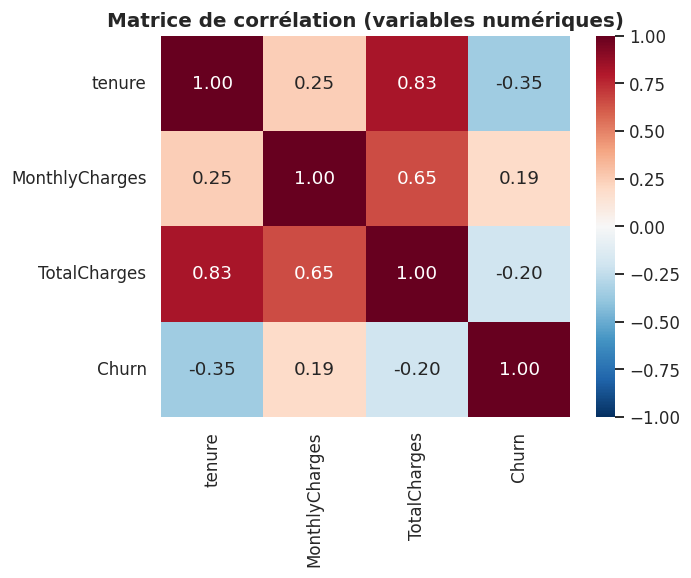

In [14]:
corr_df = df[num_vars].assign(Churn=(df["Churn"] == "Yes").astype(int))
fig, ax = plt.subplots(figsize=(6, 4.5))
sns.heatmap(corr_df.corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Matrice de corrélation (variables numériques)")
plt.show()

`TotalCharges` est fortement corrélée à `tenure` (0,83) : elle apporte peu d'information nouvelle. On la conserve car les modèles régularisés et les arbres gèrent bien cette redondance.

### 📝 Synthèse de l'EDA
| Facteur de risque | Observation |
|---|---|
| Contrat mensuel | ~43 % de churn vs ~3 % en contrat 2 ans |
| Faible ancienneté | > 50 % de churn sur les 6 premiers mois |
| Fibre optique | ~42 % de churn vs ~19 % en DSL |
| Chèque électronique | ~45 % de churn |
| Pas de sécurité en ligne / support technique | ~42 % de churn |
| Facture mensuelle élevée | médiane de 80 $ chez les churners vs 64 $ |

## 5. Feature engineering

On crée une variable **`NumServices`** : le nombre de services souscrits par le client. L'intuition : plus un client utilise de services, plus il est « ancré » chez l'opérateur et plus le coût de changement est élevé.

In [15]:
services = ["PhoneService", "MultipleLines", "OnlineSecurity", "OnlineBackup",
            "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]

def add_features(data: pd.DataFrame) -> pd.DataFrame:
    data = data.copy()
    data["NumServices"] = (data[services] == "Yes").sum(axis=1) + (data["InternetService"] != "No").astype(int)
    return data

df = add_features(df)
df.groupby("NumServices")["Churn"].apply(lambda s: (s == "Yes").mean() * 100).round(1).to_frame("Taux de churn (%)").T

NumServices,1,2,3,4,5,6,7,8,9
Taux de churn (%),10.9,31.0,44.9,36.5,31.3,25.6,22.5,12.4,5.3


**Constat :** la relation n'est **pas linéaire**. Les clients avec 1 seul service (souvent le téléphone seul, sans Internet) partent peu (~11 %), le churn culmine à 3 services (~45 %) puis diminue régulièrement jusqu'à ~5 % pour les clients qui ont tout souscrit. L'hypothèse de « l'ancrage » se vérifie donc **chez les clients Internet** : au-delà de 3 services, chaque service supplémentaire réduit le risque. Les modèles à base d'arbres (XGBoost) sont bien adaptés pour capter ce type de relation.

## 6. Préparation des données pour la modélisation

- Suppression de `customerID` (identifiant sans valeur prédictive).
- Encodage de la cible : `Yes` → 1, `No` → 0.
- Découpage **train (80 %) / test (20 %) stratifié** pour conserver la proportion de churn dans les deux jeux. Le jeu de test n'est utilisé **qu'une seule fois**, pour l'évaluation finale.
- Prétraitement dans un **`Pipeline` scikit-learn** (standardisation des numériques + one-hot encoding des catégorielles), appris uniquement sur les données d'entraînement → **aucune fuite de données**.

In [16]:
X = df.drop(columns=["customerID", "Churn"])
y = (df["Churn"] == "Yes").astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print(f"Train : {X_train.shape}  |  taux de churn = {y_train.mean():.3f}")
print(f"Test  : {X_test.shape}  |  taux de churn = {y_test.mean():.3f}")

numeric_features = ["tenure", "MonthlyCharges", "TotalCharges", "NumServices"]
categorical_features = [c for c in X.columns if c not in numeric_features]

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),
    ("cat", OneHotEncoder(drop="if_binary", handle_unknown="ignore"), categorical_features),
])

Train : (5634, 20)  |  taux de churn = 0.265
Test  : (1409, 20)  |  taux de churn = 0.265


## 7. Modèles de référence et comparaison

On compare 4 approches en **validation croisée stratifiée à 5 plis** sur le jeu d'entraînement :

| Modèle | Rôle |
|---|---|
| `DummyClassifier` | Référence naïve (prédit toujours la classe majoritaire) |
| Régression logistique | Modèle linéaire simple et interprétable |
| Random Forest | Ensemble d'arbres, capture les non-linéarités |
| XGBoost | Gradient boosting, souvent le plus performant sur données tabulaires |

Le déséquilibre des classes est pris en compte via `class_weight="balanced"` (ou `scale_pos_weight` pour XGBoost), ce qui pénalise davantage les erreurs sur les churners.

In [17]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = ["roc_auc", "average_precision", "f1", "recall", "precision", "accuracy"]
pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

models = {
    "Baseline (Dummy)": DummyClassifier(strategy="most_frequent"),
    "Régression logistique": LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced",
                                            random_state=RANDOM_STATE, n_jobs=-1),
    "XGBoost": XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4, subsample=0.8,
                             colsample_bytree=0.8, scale_pos_weight=pos_weight,
                             random_state=RANDOM_STATE, n_jobs=-1, eval_metric="logloss"),
}

cv_results = {}
for name, model in models.items():
    pipe = Pipeline([("preprocessor", preprocessor), ("model", model)])
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    cv_results[name] = {m: scores[f"test_{m}"].mean() for m in scoring}
    cv_results[name]["roc_auc_std"] = scores["test_roc_auc"].std()

cv_df = pd.DataFrame(cv_results).T.rename(columns={
    "roc_auc": "ROC-AUC", "average_precision": "PR-AUC", "f1": "F1", "recall": "Rappel",
    "precision": "Précision", "accuracy": "Accuracy", "roc_auc_std": "ROC-AUC (écart-type)"})
cv_df.round(3)

,ROC-AUC,PR-AUC,F1,Rappel,Précision,Accuracy,ROC-AUC (écart-type)
Baseline (Dummy),0.500,0.265,0.000,0.000,0.000,0.735,0.000
Régression logistique,0.846,0.660,0.629,0.801,0.517,0.749,0.012
Random Forest,0.844,0.656,0.632,0.729,0.558,0.775,0.010
XGBoost,0.844,0.664,0.633,0.774,0.536,0.762,0.010


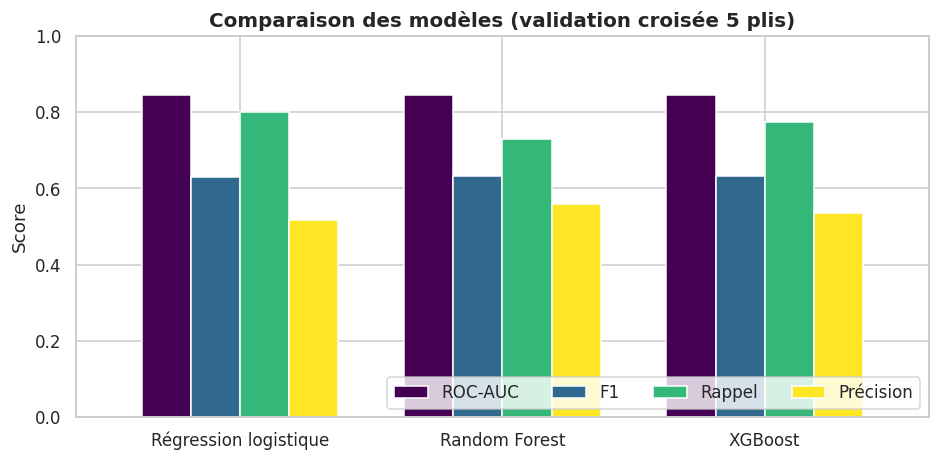

In [18]:
fig, ax = plt.subplots(figsize=(10, 4.5))
cv_df[["ROC-AUC", "F1", "Rappel", "Précision"]].drop("Baseline (Dummy)").plot.bar(ax=ax, rot=0, width=0.75,
                                                                                    colormap="viridis")
ax.set_title("Comparaison des modèles (validation croisée 5 plis)")
ax.set_ylim(0, 1); ax.set_ylabel("Score")
ax.legend(loc="lower right", ncol=4)
save_fig("07_model_comparison")
plt.show()

**Lecture :**
- La baseline a une accuracy de ~73 % mais un **rappel de 0** : elle ne détecte aucun churner. Cela confirme que l'accuracy n'est pas une bonne métrique ici.
- Les trois modèles atteignent une **ROC-AUC d'environ 0,84-0,85**, avec des performances très proches. Sur ce jeu de données, la relation entre les variables et le churn est en grande partie **linéaire** : les modèles complexes n'apportent pas de gain significatif.
- Grâce à la pondération des classes, les modèles détectent **75 à 80 % des churners**.

## 8. Optimisation des hyperparamètres

On optimise les deux candidats les plus intéressants avec pour critère la **ROC-AUC** en validation croisée :
- **Régression logistique** (`GridSearchCV`) : force et type de régularisation.
- **XGBoost** (`RandomizedSearchCV`) : profondeur, taux d'apprentissage, nombre d'arbres, sous-échantillonnage…

In [19]:
# --- Régression logistique ---
lr_pipe = Pipeline([("preprocessor", preprocessor),
                    ("model", LogisticRegression(max_iter=5000, class_weight="balanced",
                                                 solver="liblinear", random_state=RANDOM_STATE))])
lr_grid = GridSearchCV(lr_pipe, {"model__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10],
                                 "model__penalty": ["l1", "l2"]},
                       cv=cv, scoring="roc_auc", n_jobs=-1)
lr_grid.fit(X_train, y_train)
print("Régression logistique — meilleurs paramètres :", lr_grid.best_params_)
print(f"Régression logistique — ROC-AUC CV : {lr_grid.best_score_:.4f}")

Régression logistique — meilleurs paramètres : {'model__C': 10, 'model__penalty': 'l2'}
Régression logistique — ROC-AUC CV : 0.8462


In [20]:
# --- XGBoost ---
xgb_pipe = Pipeline([("preprocessor", preprocessor),
                     ("model", XGBClassifier(scale_pos_weight=pos_weight, random_state=RANDOM_STATE,
                                             n_jobs=-1, eval_metric="logloss"))])
xgb_params = {
    "model__n_estimators": [100, 200, 300, 500],
    "model__learning_rate": [0.01, 0.03, 0.05, 0.1],
    "model__max_depth": [2, 3, 4, 5],
    "model__min_child_weight": [1, 3, 5, 10],
    "model__subsample": [0.7, 0.8, 1.0],
    "model__colsample_bytree": [0.6, 0.8, 1.0],
    "model__reg_lambda": [0.5, 1, 5, 10],
}
xgb_search = RandomizedSearchCV(xgb_pipe, xgb_params, n_iter=40, cv=cv, scoring="roc_auc",
                                random_state=RANDOM_STATE, n_jobs=-1)
xgb_search.fit(X_train, y_train)
print("XGBoost — meilleurs paramètres :", xgb_search.best_params_)
print(f"XGBoost — ROC-AUC CV : {xgb_search.best_score_:.4f}")

XGBoost — meilleurs paramètres : {'model__subsample': 0.7, 'model__reg_lambda': 0.5, 'model__n_estimators': 500, 'model__min_child_weight': 3, 'model__max_depth': 3, 'model__learning_rate': 0.01, 'model__colsample_bytree': 1.0}
XGBoost — ROC-AUC CV : 0.8500


In [21]:
tuned = {"Régression logistique": lr_grid, "XGBoost": xgb_search}
best_name = max(tuned, key=lambda k: tuned[k].best_score_)
final_model = tuned[best_name].best_estimator_
print(f"✅ Modèle retenu : {best_name} (ROC-AUC CV = {tuned[best_name].best_score_:.4f})")

✅ Modèle retenu : XGBoost (ROC-AUC CV = 0.8500)


**Lecture :** après optimisation, **XGBoost** passe légèrement devant (ROC-AUC CV ≈ 0,850 contre ≈ 0,846 pour la régression logistique). Les meilleurs paramètres privilégient des **arbres peu profonds** (`max_depth=3`) et un **apprentissage lent** (`learning_rate=0.01`, 500 arbres) : un modèle prudent qui limite le surapprentissage.

L'écart reste faible : la régression logistique est une alternative très crédible, plus simple à déployer et à expliquer. On la conserve pour l'interprétation (section 11).

## 9. Évaluation finale sur le jeu de test

Le jeu de test (20 % des données, jamais vu pendant l'entraînement ni l'optimisation) donne une estimation honnête de la performance en production.

In [22]:
# Modèles optimisés + Random Forest de référence, réentraînés sur tout le train
rf_pipe = Pipeline([("preprocessor", preprocessor), ("model", models["Random Forest"])]).fit(X_train, y_train)
eval_models = {"Régression logistique": lr_grid.best_estimator_,
               "Random Forest": rf_pipe,
               "XGBoost": xgb_search.best_estimator_}

test_rows = {}
probas = {}
for name, m in eval_models.items():
    p = m.predict_proba(X_test)[:, 1]
    pred = (p >= 0.5).astype(int)
    probas[name] = p
    test_rows[name] = {"ROC-AUC": roc_auc_score(y_test, p), "PR-AUC": average_precision_score(y_test, p),
                       "F1": f1_score(y_test, pred), "Rappel": recall_score(y_test, pred),
                       "Précision": precision_score(y_test, pred)}
test_df = pd.DataFrame(test_rows).T
test_df.round(3)

,ROC-AUC,PR-AUC,F1,Rappel,Précision
Régression logistique,0.841,0.627,0.614,0.783,0.505
Random Forest,0.840,0.648,0.634,0.743,0.553
XGBoost,0.847,0.663,0.630,0.807,0.516


In [23]:
y_proba = final_model.predict_proba(X_test)[:, 1]
y_pred = (y_proba >= 0.5).astype(int)
print(f"=== {best_name} — seuil 0,5 ===\n")
print(classification_report(y_test, y_pred, target_names=["Reste (0)", "Churn (1)"], digits=3))

=== XGBoost — seuil 0,5 ===

              precision    recall  f1-score   support

   Reste (0)      0.913     0.727     0.809      1035
   Churn (1)      0.516     0.807     0.630       374

    accuracy                          0.748      1409
   macro avg      0.714     0.767     0.719      1409
weighted avg      0.807     0.748     0.761      1409



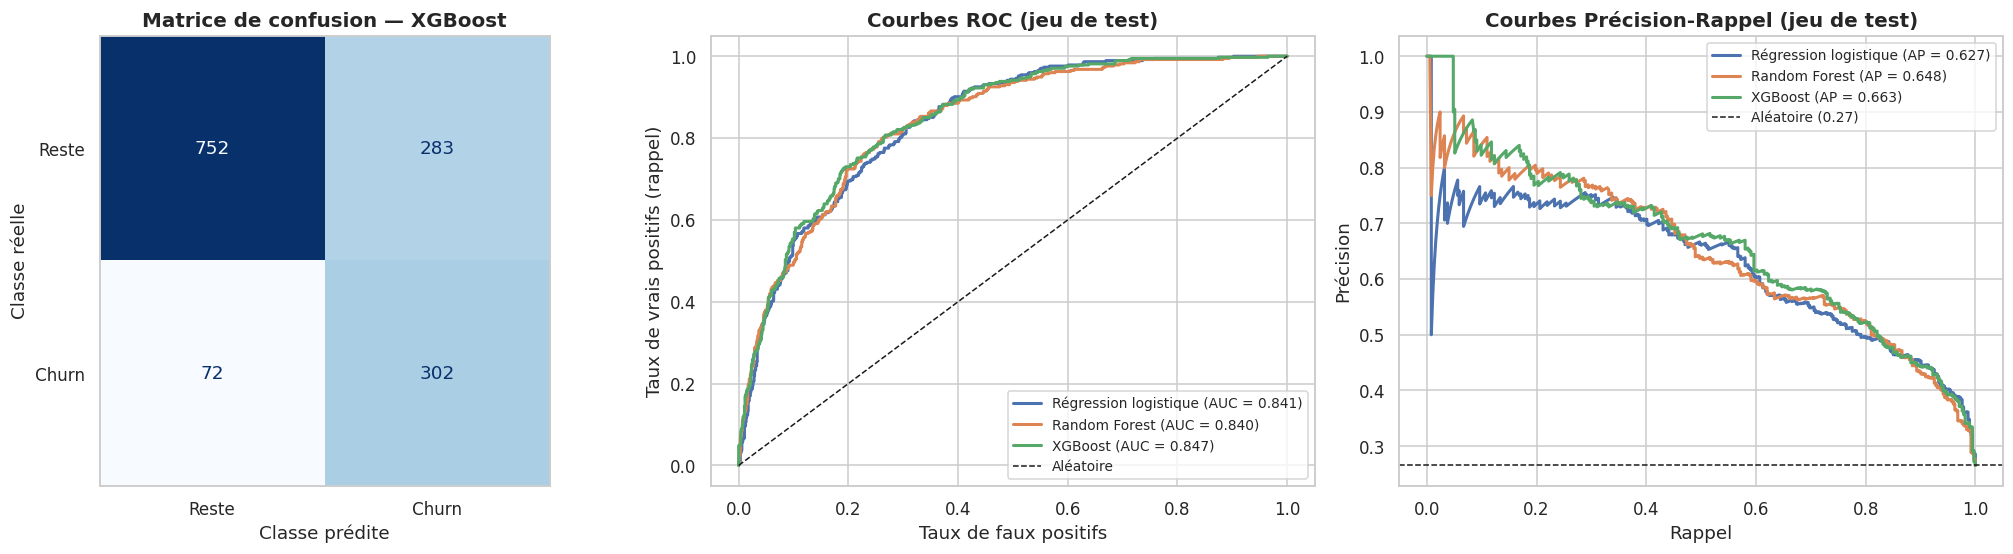

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5.2))

# Matrice de confusion
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["Reste", "Churn"],
                                        cmap="Blues", ax=axes[0], colorbar=False)
axes[0].set_title(f"Matrice de confusion — {best_name}")
axes[0].set_xlabel("Classe prédite"); axes[0].set_ylabel("Classe réelle")
axes[0].grid(False)

# Courbes ROC
for name, p in probas.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[1].plot(fpr, tpr, lw=2, label=f"{name} (AUC = {roc_auc_score(y_test, p):.3f})")
axes[1].plot([0, 1], [0, 1], "k--", lw=1, label="Aléatoire")
axes[1].set_title("Courbes ROC (jeu de test)")
axes[1].set_xlabel("Taux de faux positifs"); axes[1].set_ylabel("Taux de vrais positifs (rappel)")
axes[1].legend(loc="lower right", fontsize=9)

# Courbes Précision-Rappel
for name, p in probas.items():
    prec, rec, _ = precision_recall_curve(y_test, p)
    axes[2].plot(rec, prec, lw=2, label=f"{name} (AP = {average_precision_score(y_test, p):.3f})")
axes[2].axhline(y_test.mean(), color="k", ls="--", lw=1, label=f"Aléatoire ({y_test.mean():.2f})")
axes[2].set_title("Courbes Précision-Rappel (jeu de test)")
axes[2].set_xlabel("Rappel"); axes[2].set_ylabel("Précision")
axes[2].legend(loc="upper right", fontsize=9)

plt.tight_layout()
save_fig("08_evaluation")
plt.show()

Les performances sur le jeu de test sont **cohérentes avec la validation croisée** : pas de surapprentissage. Au seuil par défaut de 0,5, le modèle identifie environ **4 churners sur 5**, au prix d'un certain nombre de faux positifs (clients fidèles signalés à tort).

Mais le seuil de 0,5 est arbitraire. La bonne question est : **quel seuil rapporte le plus à l'entreprise ?**

## 10. Choix du seuil de décision orienté métier

On simule une **campagne de rétention** : chaque client dont la probabilité de churn dépasse le seuil reçoit une offre.

**Hypothèses (à ajuster avec les équipes métier) :**
| Paramètre | Valeur | Signification |
|---|---|---|
| Coût de l'offre | 50 $ | Remise ou geste commercial, payé pour **chaque** client ciblé |
| Taux de succès | 30 % | Part des vrais churners ciblés qui restent grâce à l'offre |
| Valeur d'un client retenu | 12 × `MonthlyCharges` | Revenu conservé sur un an, **propre à chaque client** |

**Gain net** = Σ (vrais churners ciblés × 30 % × valeur annuelle) − 50 $ × (nombre de clients ciblés)

> 🔒 **Bonne pratique :** le seuil est choisi sur des **prédictions hors-échantillon du jeu d'entraînement** (`cross_val_predict`), puis appliqué **une seule fois** au jeu de test. Choisir le seuil directement sur le test le rendrait optimiste.

In [25]:
OFFER_COST = 50
SUCCESS_RATE = 0.30
THRESHOLDS = np.round(np.arange(0.05, 0.91, 0.01), 2)

def campaign_gain(proba, y_true, monthly_charges, threshold):
    """Gain net d'une campagne ciblant les clients dont la proba >= seuil."""
    targeted = proba >= threshold
    tp = targeted & (y_true == 1)
    gain = (12 * monthly_charges[tp] * SUCCESS_RATE).sum() - OFFER_COST * targeted.sum()
    return gain, targeted.sum(), tp.sum() / y_true.sum(), tp.sum() / targeted.sum() if targeted.sum() else np.nan

def profit_curve(proba, y_true, monthly_charges):
    rows = [campaign_gain(proba, y_true, monthly_charges, t) for t in THRESHOLDS]
    return pd.DataFrame(rows, columns=["gain_net", "clients_cibles", "rappel", "precision"]).assign(seuil=THRESHOLDS)

# 1) Choix du seuil sur les prédictions hors-échantillon (train)
oof_proba = cross_val_predict(final_model, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
profit_train = profit_curve(oof_proba, y_train.values, X_train["MonthlyCharges"].values)
best_threshold = float(profit_train.loc[profit_train["gain_net"].idxmax(), "seuil"])
print(f"Seuil optimal (choisi sur le train, hors-échantillon) : {best_threshold:.2f}\n")

# 2) Évaluation sur le jeu de test
y_te, mc_te = y_test.values, X_test["MonthlyCharges"].values
scenarios = {"Seuil optimisé": best_threshold, "Seuil par défaut (0,5)": 0.5, "Cibler tous les clients": 0.0}
res = {}
for label, t in scenarios.items():
    g, n, r, p = campaign_gain(y_proba, y_te, mc_te, t)
    res[label] = {"Seuil": t, "Clients ciblés": n, "Rappel": r, "Précision": p, "Gain net ($)": g}
business_df = pd.DataFrame(res).T
business_df.style.format({"Seuil": "{:.2f}", "Clients ciblés": "{:.0f}", "Rappel": "{:.0%}",
                          "Précision": "{:.0%}", "Gain net ($)": "{:,.0f}"})

Seuil optimal (choisi sur le train, hors-échantillon) : 0.37



,Seuil,Clients ciblés,Rappel,Précision,Gain net ($)
Seuil optimisé,0.37,721,88%,46%,"52,462"
"Seuil par défaut (0,5)",0.50,585,81%,52%,"51,650"
Cibler tous les clients,0.00,1409,100%,27%,"27,524"


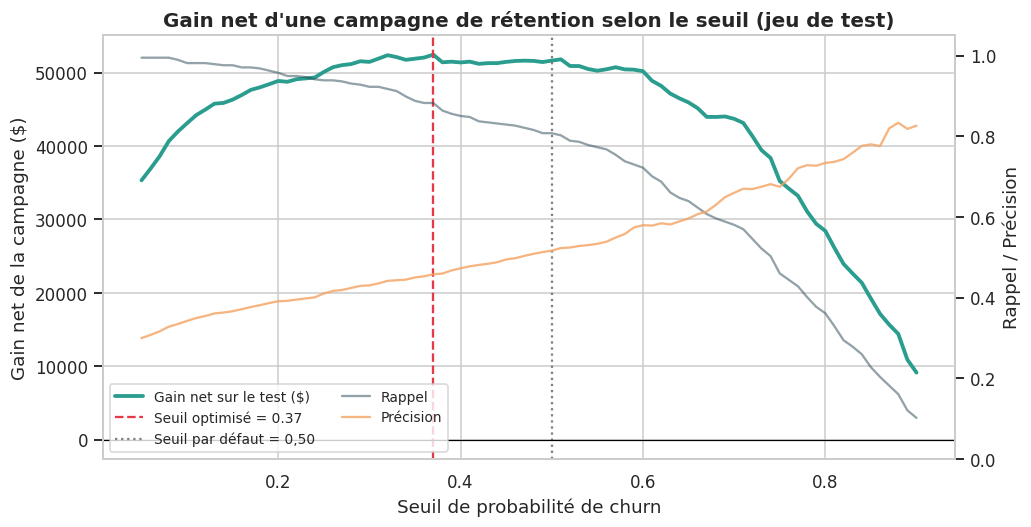

In [26]:
profit_test = profit_curve(y_proba, y_te, mc_te)

fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.plot(profit_test["seuil"], profit_test["gain_net"], color="#2A9D8F", lw=2.5, label="Gain net sur le test ($)")
ax1.axvline(best_threshold, color="#E63946", ls="--", lw=1.5, label=f"Seuil optimisé = {best_threshold:.2f}")
ax1.axvline(0.5, color="grey", ls=":", lw=1.5, label="Seuil par défaut = 0,50")
ax1.axhline(0, color="black", lw=0.8)
ax1.set_xlabel("Seuil de probabilité de churn"); ax1.set_ylabel("Gain net de la campagne ($)")
ax2 = ax1.twinx()
ax2.plot(profit_test["seuil"], profit_test["rappel"], color="#264653", alpha=0.5, lw=1.5, label="Rappel")
ax2.plot(profit_test["seuil"], profit_test["precision"], color="#F4A261", alpha=0.8, lw=1.5, label="Précision")
ax2.set_ylabel("Rappel / Précision"); ax2.set_ylim(0, 1.05); ax2.grid(False)
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="lower left", fontsize=9, ncol=2)
ax1.set_title("Gain net d'une campagne de rétention selon le seuil (jeu de test)")
save_fig("09_business_threshold")
plt.show()

**Lecture :**
- Cibler les clients avec le modèle rapporte **environ deux fois plus** que d'envoyer l'offre à tous les clients : on évite de payer des offres pour des clients qui ne comptaient pas partir.
- Le gain forme un **plateau assez large** (entre ~0,3 et ~0,6) : la décision est robuste, un léger changement de seuil ne change pas fondamentalement le résultat.
- Le seuil optimisé est **plus bas que 0,5** : quand un client perdu coûte plus cher qu'une offre, il vaut mieux accepter plus de faux positifs pour attraper davantage de churners.

> ⚠️ Les hypothèses (coût, taux de succès, valeur client) sont illustratives. En entreprise, elles seraient fournies par le marketing et validées par un **test A/B**.

## 11. Interprétabilité du modèle

### 11.1 Un modèle logistique dédié à l'interprétation

Lire directement les coefficients de la régression logistique optimisée serait **trompeur** : plusieurs variables sont **redondantes** (`MonthlyCharges` est quasiment la somme des services souscrits, `TotalCharges ≈ tenure × MonthlyCharges`, et la modalité « No internet service » est répétée dans 6 colonnes). Avec cette **multicolinéarité**, les coefficients se compensent entre eux et peuvent même changer de signe.

On entraîne donc une version **simplifiée et régularisée**, pensée pour l'explication :
- suppression de `MonthlyCharges`, `TotalCharges` et `NumServices` (redondants avec les services et l'ancienneté) ;
- « No internet service » / « No phone service » regroupés avec « No » (l'information est déjà portée par `InternetService` et `PhoneService`) ;
- encodage avec une **modalité de référence** (`drop="first"`) : chaque coefficient se lit par rapport au profil de référence (contrat mensuel, DSL, virement bancaire, etc.).

Si ce modèle reste aussi performant, ses coefficients sont une explication fiable du churn.

ROC-AUC CV du modèle interprétable : 0.8448  (vs 0.8462 pour la version complète)


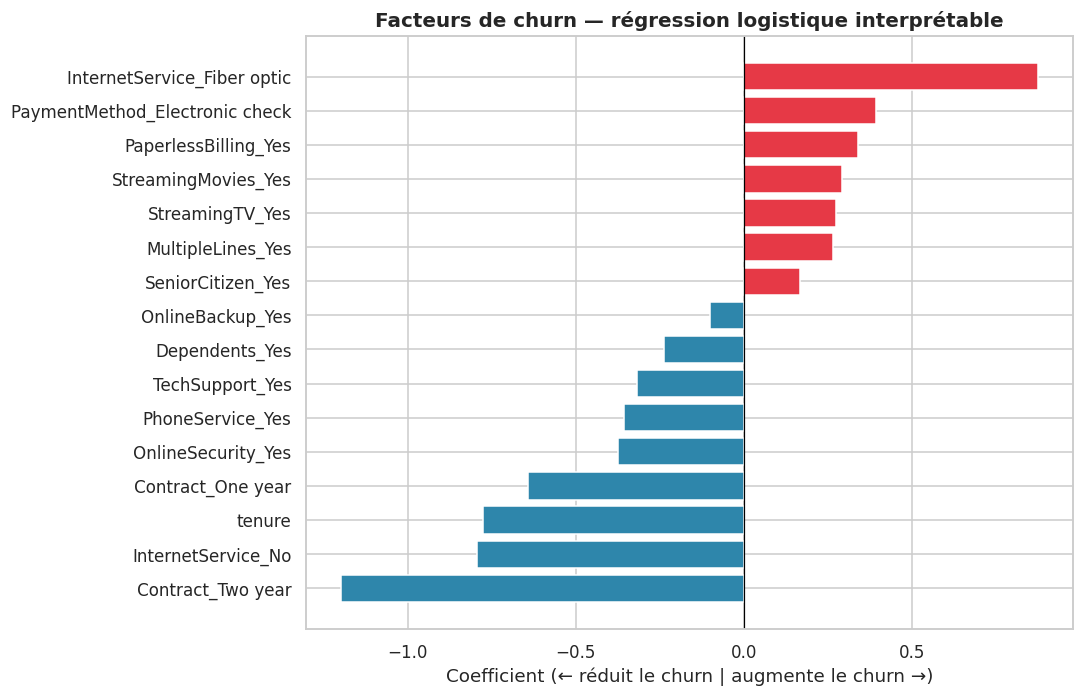

,coef,odds_ratio
feature,,
InternetService_Fiber optic,0.88,2.40
PaymentMethod_Electronic check,0.39,1.48
PaperlessBilling_Yes,0.34,1.40
StreamingMovies_Yes,0.29,1.34
StreamingTV_Yes,0.27,1.32
MultipleLines_Yes,0.27,1.30
SeniorCitizen_Yes,0.17,1.18
OnlineBackup_Yes,-0.10,0.90
Dependents_Yes,-0.24,0.79


In [27]:
def simplify(data: pd.DataFrame) -> pd.DataFrame:
    data = data.copy()
    for col in ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]:
        data[col] = data[col].replace("No internet service", "No")
    data["MultipleLines"] = data["MultipleLines"].replace("No phone service", "No")
    return data.drop(columns=["MonthlyCharges", "TotalCharges", "NumServices"])

X_train_simple = simplify(X_train)
cat_simple = [c for c in X_train_simple.columns if c != "tenure"]
# Modalités de référence explicites pour une lecture naturelle
categories = [sorted(X_train_simple[c].unique(), key=lambda v: (v not in {"No", "Month-to-month", "DSL",
              "Bank transfer (automatic)", "Female"}, v)) for c in cat_simple]

interp_lr = Pipeline([
    ("preprocessor", ColumnTransformer([
        ("num", StandardScaler(), ["tenure"]),
        ("cat", OneHotEncoder(drop="first", categories=categories), cat_simple)])),
    ("model", LogisticRegression(C=0.1, max_iter=5000, class_weight="balanced", random_state=RANDOM_STATE)),
])
auc_simple = cross_validate(interp_lr, X_train_simple, y_train, cv=cv, scoring="roc_auc")["test_score"].mean()
print(f"ROC-AUC CV du modèle interprétable : {auc_simple:.4f}  (vs {lr_grid.best_score_:.4f} pour la version complète)")
interp_lr.fit(X_train_simple, y_train)

names = [f.split("__", 1)[1] for f in interp_lr.named_steps["preprocessor"].get_feature_names_out()]
coefs = (pd.DataFrame({"feature": names, "coef": interp_lr.named_steps["model"].coef_[0]})
         .assign(odds_ratio=lambda d: np.exp(d["coef"]))
         .sort_values("coef"))
coefs = coefs[coefs["coef"].abs() > 0.05]

fig, ax = plt.subplots(figsize=(9, 7))
colors = ["#2E86AB" if c < 0 else "#E63946" for c in coefs["coef"]]
ax.barh(coefs["feature"], coefs["coef"], color=colors)
ax.axvline(0, color="black", lw=0.8)
ax.set_title("Facteurs de churn — régression logistique interprétable")
ax.set_xlabel("Coefficient (← réduit le churn | augmente le churn →)")
save_fig("10_logreg_coefficients")
plt.show()

coefs.sort_values("coef", ascending=False).round(2).set_index("feature")

**Lecture** (toutes choses égales par ailleurs, par rapport au profil de référence) :
- 🔴 **Fibre optique** : c'est le facteur aggravant le plus fort — les chances de churn sont multipliées par ~2,4 par rapport au DSL.
- 🔴 **Chèque électronique**, **facturation dématérialisée**, **streaming** et **senior** augmentent aussi le risque.
- 🔵 **Contrat deux ans** (odds ÷ ~3,3) et **un an** (÷ ~1,9) sont les facteurs protecteurs les plus puissants.
- 🔵 L'**ancienneté** réduit fortement le risque, tout comme la **sécurité en ligne** et le **support technique**.
- ⚪ Le **genre** et le fait d'avoir un **partenaire** n'ont quasiment aucun effet une fois les autres variables prises en compte.

### 11.2 Importance par permutation (modèle final)
Méthode indépendante du modèle : on mélange aléatoirement une variable dans le jeu de test et on mesure la **baisse de ROC-AUC**. Plus la baisse est forte, plus la variable est importante.

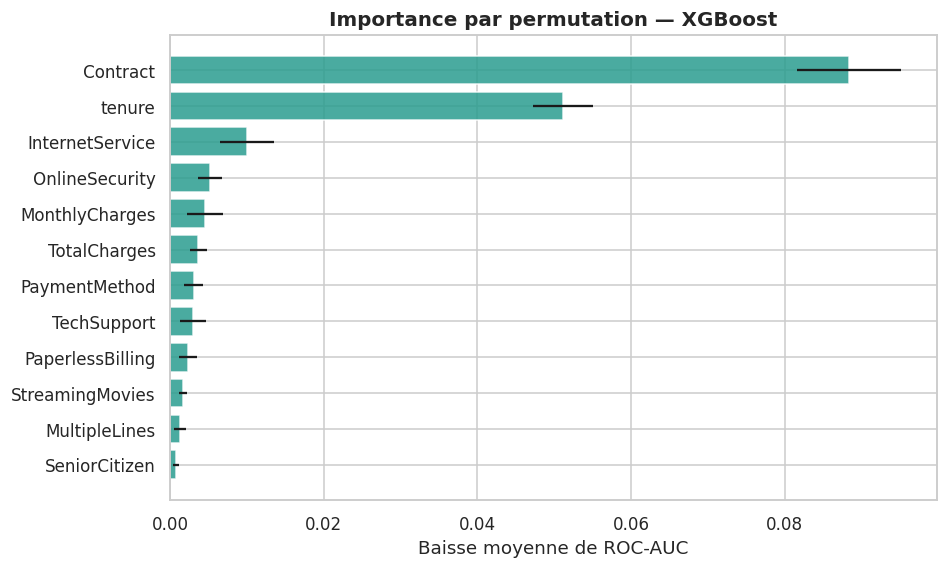

In [28]:
perm = permutation_importance(final_model, X_test, y_test, scoring="roc_auc",
                              n_repeats=20, random_state=RANDOM_STATE, n_jobs=-1)
perm_df = (pd.DataFrame({"feature": X_test.columns, "importance": perm.importances_mean,
                         "std": perm.importances_std})
           .sort_values("importance", ascending=True).tail(12))

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(perm_df["feature"], perm_df["importance"], xerr=perm_df["std"], color="#2A9D8F", alpha=0.85)
ax.set_title(f"Importance par permutation — {best_name}")
ax.set_xlabel("Baisse moyenne de ROC-AUC")
save_fig("11_permutation_importance")
plt.show()

Les deux méthodes convergent avec l'EDA : **ancienneté**, **type de contrat**, **service Internet (fibre)** et **niveau de facturation** sont les principaux déterminants du churn.

## 12. Recommandations métier

| # | Levier | Action proposée | Justification (données) |
|---|---|---|---|
| 1 | **Contrats longs** | Inciter les clients mensuels à passer à un contrat 1 ou 2 ans (remise, mois offert) | ~43 % de churn en mensuel vs ~3 % en 2 ans |
| 2 | **Onboarding** | Programme d'accompagnement renforcé sur les 6 premiers mois (appel de bienvenue, suivi qualité) | Plus de 50 % de churn sur les 6 premiers mois |
| 3 | **Offre fibre** | Enquêter sur la satisfaction des clients fibre (prix, pannes, débit) | ~42 % de churn vs ~19 % en DSL |
| 4 | **Paiement automatique** | Encourager le prélèvement / la carte bancaire automatique | ~45 % de churn en chèque électronique vs ~15 % en automatique |
| 5 | **Services d'accompagnement** | Proposer `OnlineSecurity` / `TechSupport` en essai gratuit | Leur présence est associée à un churn nettement plus faible |
| 6 | **Ciblage** | Utiliser le score du modèle avec le seuil optimisé pour prioriser les campagnes | Gain net supérieur au ciblage de masse (section 10) |

## 13. Sauvegarde du modèle

Le pipeline complet (prétraitement + modèle) est sauvegardé : il peut être rechargé pour scorer de nouveaux clients à partir des données brutes (voir `src/predict.py`).

In [29]:
artifact = {"pipeline": final_model, "threshold": best_threshold, "model_name": best_name}
joblib.dump(artifact, MODEL_DIR / "churn_model.joblib")
print("Modèle sauvegardé dans", MODEL_DIR / "churn_model.joblib")

# Exemple : scorer 5 clients du jeu de test
example = X_test.head(5).copy()
example["proba_churn"] = final_model.predict_proba(example)[:, 1].round(3)
example["a_cibler"] = example["proba_churn"] >= artifact["threshold"]
example[["tenure", "Contract", "InternetService", "MonthlyCharges", "proba_churn", "a_cibler"]]

Modèle sauvegardé dans ../models/churn_model.joblib


,tenure,Contract,InternetService,MonthlyCharges,proba_churn,a_cibler
437,72,Two year,Fiber optic,114.05,0.068,False
2280,8,Month-to-month,Fiber optic,100.15,0.870,True
2235,41,One year,DSL,78.35,0.155,False
4460,18,Month-to-month,Fiber optic,78.20,0.604,True
3761,72,Two year,DSL,82.65,0.045,False


## 14. Conclusion et pistes d'amélioration

### ✅ Résultats
- Analyse complète de **7 043 clients** : les facteurs de churn sont clairement identifiés (contrat mensuel, faible ancienneté, fibre optique, chèque électronique, absence de services d'accompagnement).
- Modèle final (**XGBoost** optimisé) avec une **ROC-AUC de ~0,85 sur le jeu de test**, qui détecte **~80 % des clients qui partent** au seuil de 0,5.
- Le score est traduit en **décision métier** : un seuil optimisé qui maximise le gain d'une campagne de rétention, environ **2× plus rentable** qu'un ciblage de masse.
- Pipeline reproductible, sans fuite de données, sauvegardé et réutilisable.

### 🔭 Pistes d'amélioration
- **Données** : ajouter des variables comportementales (appels au service client, incidents réseau, évolution de consommation) — souvent les plus prédictives en pratique.
- **Modélisation** : tester LightGBM/CatBoost, enrichir le feature engineering, calibrer les probabilités (`CalibratedClassifierCV`), expliquer les prédictions individuelles avec **SHAP**.
- **Survie** : modéliser *quand* un client va partir (analyse de survie, modèle de Cox) et pas seulement *s'il* va partir.
- **Mise en production** : exposer le modèle via une API (FastAPI) ou une démo interactive (Streamlit), et suivre la dérive des données dans le temps.
- **Validation terrain** : mesurer l'impact réel des actions de rétention par un **test A/B**.